# Bowl Escape — Multi-Rodent Trail Render

Loads a bowl_escape task transfer checkpoint, generates a rollout,
and renders a multi-rodent trail visualization with interactive camera controls
and high-res export.

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import io
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import PIL.Image
from PIL import ImageDraw, ImageFont
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
import ipywidgets as widgets
from IPython.display import display as ipy_display

# Suppress MuJoCo CCD iteration warnings from bowl heightfield
mujoco.set_mju_user_warning(lambda msg: None)

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import bowl_escape
from scamper.environment.rodent.bowl_escape import add_bowl_hfield

from scamper.agent.task_transfer.bowl_escape.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.bowl_escape.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.bowl_escape.scratch_networks import (
    make_scratch_ppo_networks,
)

In [14]:
# === Checkpoint & rollout configuration ===
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/bowl_escape_checkpoints/260302_135226_241697"
CHECKPOINT_STEP = None  # None = latest step
NAME = "bowl_escape"

EPISODE_LENGTH = 1000
SEED = 0

# Single-camera video rendering
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# === Trail configuration ===
TRAIL_NUM_FRAMES = 10  # rodent copies (ignored if override is set)
TRAIL_T_START = 0
TRAIL_T_END = 135
TRAIL_TIMESTEPS_OVERRIDE = []  # explicit timesteps; empty = linspace

# Trajectory trace line
TRAIL_LINE_STEP = 5
TRAIL_LINE_RADIUS = 0.003
TRAIL_LINE_RGB = (189, 19, 0)
TRAIL_LINE_ALPHA = 0.8

# Initial camera (world coordinates)
TRAIL_CAM_POS = [0.0, -2.5, 2.0]
TRAIL_CAM_LOOKAT = [0.0, 0.0, 0.0]
TRAIL_CAM_FOVY = 45

# High-res render resolution
TRAIL_RENDER_HEIGHT = 1080
TRAIL_RENDER_WIDTH = 2048

# Output directory
OUTPUT_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/bowl_escape_trails/{NAME}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

In [3]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 48
Training mode: scratch
Training metadata: {'completed_timesteps': 739246080, 'eval_step': 48, 'wandb_run_id': 'scratch_s2_260302_135226_241697', 'run_id': '260302_135226_241697', 'mode': 'scratch'}


In [4]:
# Load frozen networks from the prior checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

In [5]:
# Create environment config from checkpoint
env_cfg = bowl_escape.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.reward_terms = {
    "escape": {"weight": config["env"]["reward_weights"]["escape"]},
}

# Set actuator type from checkpoint config (matches train.py logic)
if mode == "scratch":
    env_cfg.torque_actuators = config.get("scratch", {}).get("torque_actuators", True)
else:
    env_cfg.torque_actuators = True

# Resolve the walker XML path for later use in MjSpec model building
walker_xml = str(env_cfg.walker_xml_path)
arena_xml = str(rodent_consts.ARENA_XML_PATH)

print(f"XML variant: {xml_variant}")
print(f"Walker XML: {walker_xml}")
print(f"Arena XML: {arena_xml}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Torque actuators: {env_cfg.torque_actuators}")

XML variant: no-tail-collisions
Walker XML: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent_no_tail_collisions.xml
Arena XML: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/arena.xml
MuJoCo impl: warp
ctrl_dt: 0.01
Torque actuators: False


In [6]:
from mujoco import mjx

# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = bowl_escape.BowlEscape(config=env_cfg)

# Modify heightfield friction if specified in checkpoint config
hfield_friction = config["env"].get("hfield_friction")
if hfield_friction is not None:
    for i in range(base_env._mj_model.ngeom):
        if base_env._mj_model.geom_type[i] == mujoco.mjtGeom.mjGEOM_HFIELD:
            base_env._mj_model.geom_friction[i, 0] = hfield_friction
            print(f"Heightfield geom {i} friction set to: {hfield_friction}")
            break
    base_env._mjx_model = mjx.put_model(base_env._mj_model, impl=env_cfg.mujoco_impl)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode == "prior_decoder":
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=config["prior_decoder"]["deterministic_prior"],
        noise_logvar=config["prior_decoder"]["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Initial position: 0.0, 0.0, 0.009999999776482582
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Heightfield geom 0 friction set to: 1.0
Created wrapped environment for mode: scratch
Action size (policy outputs): 38


## Build Networks & Load Policy

In [7]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 10.90 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.98 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.76 ms  (cached)
Module ccd_hfield_kernel_builder__locals__ccd_hfield_kernel_da6c4a1b da6c4a1 load on device 'cuda:0' took 4.05 ms  (cached)
Module ccd_hfield_kernel_builder__locals__ccd_hfield_kernel_3a85d6fd 3a85d6f load on device 'cuda:0' took 4.01 ms  (cached)
Module ccd_hfield_kernel_builder__locals__ccd_hfield_kernel_7aa2d700 7aa2d70 load on device 'cuda:0' took 3.38 ms  (cached)
Module ccd_hfield_kernel_builder__locals__ccd_hfield_kernel_23d0e39d 23d0e39 load on device 'cuda:0' took 3.91 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 2.53 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.

E0303 15:33:41.499396  105172 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.15 = s32[] reduce(%constant.70, %constant.142), dimensions={0}, to_apply=%region_1.6, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=76}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0303 15:33:53.601266  105080 slow_operation_alarm.cc:140] The operation took 13.10204445s
Constant folding an instruction is taking > 1s:

  %reduce_sum.15 = s32[] reduce(%constant.70, %constant.142), dimensions={0}, to_apply=%region_1.6, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=76}

This isn't necessarily a bug;

Observation size: 331


In [8]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":

    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            obs_size=obs_size,
            action_size=policy_action_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )

    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [9]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}


jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Generate Rollout

In [10]:
# Generate rollout
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

print(f"Generating rollout with {EPISODE_LENGTH} steps...")
for i in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

    if (i + 1) % 100 == 0:
        print(f"  Step {i + 1}/{EPISODE_LENGTH}")

print(f"Rollout complete! {len(rollout)} states collected.")

Generating rollout with 1000 steps...
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 2.23 ms  (cached)
  Step 100/1000
  Step 200/1000
  Step 300/1000
  Step 400/1000
  Step 500/1000
  Step 600/1000
  Step 700/1000
  Step 800/1000
  Step 900/1000
  Step 1000/1000
Rollout complete! 1001 states collected.


## Extract qpos & Build Single-Rodent Model

In [11]:
# Extract qpos from rollout states
qpos = np.array([np.array(s.data.qpos) for s in rollout])
print(f"qpos shape: {qpos.shape}  (timesteps, nq)")

# Build single-rodent arena+bowl+rodent model for computing torso positions
# and rendering video. Recreate the bowl with the same rng seed as the env.
arena_spec = mujoco.MjSpec.from_file(arena_xml)
_, bowl_rng = jax.random.split(jax.random.PRNGKey(0))
bowl_cfg = bowl_escape.default_config()
arena_spec, _ = add_bowl_hfield(
    bowl_rng,
    arena_spec,
    hsize=bowl_cfg.bowl_hsize,
    vsize=bowl_cfg.bowl_vsize,
    sigma=bowl_cfg.bowl_sigma,
    amplitude=bowl_cfg.bowl_amplitude,
)

rodent_spec = mujoco.MjSpec.from_file(walker_xml)
frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")

# Add directional overhead light to illuminate the entire heightfield
light = arena_spec.worldbody.add_light(name="overhead")
light.pos = [0, 0, 10]
light.dir = [0, 0, -1]
light.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
light.diffuse = [1.0, 1.0, 1.0]
light.specular = [0.3, 0.3, 0.3]

model = arena_spec.compile()
data = mujoco.MjData(model)

print(f"Single-rodent model nq: {model.nq} (qpos dim: {qpos.shape[1]})")
assert model.nq == qpos.shape[1], f"Model nq ({model.nq}) != qpos dim ({qpos.shape[1]})"

qpos shape: (1001, 74)  (timesteps, nq)
Single-rodent model nq: 74 (qpos dim: 74)


## Render Video (optional)

In [12]:
# Render video with frame burnin
camera = RENDER_CAMERA
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)
renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

try:
    font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 24
    )
except OSError:
    font = ImageFont.load_default(size=24)

video_frames = []
for t in range(qpos.shape[0]):
    data.qpos[:] = qpos[t]
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    frame = renderer.render().copy()

    img = PIL.Image.fromarray(frame)
    draw = ImageDraw.Draw(img)
    draw.text((10, 10), str(t), fill=(255, 255, 255), font=font)
    video_frames.append(np.array(img))

renderer.close()
media.show_video(video_frames, fps=RENDER_FPS)

This browser does not support the video tag.


## Multi-Rodent Trail Scene

In [15]:
# Build multi-rodent trail with interactive camera

# --- Determine trail timesteps ---
if TRAIL_TIMESTEPS_OVERRIDE:
    trail_indices = np.array(TRAIL_TIMESTEPS_OVERRIDE, dtype=int)
    trail_num_frames = len(trail_indices)
else:
    trail_indices = np.linspace(TRAIL_T_START, TRAIL_T_END, TRAIL_NUM_FRAMES, dtype=int)
    trail_num_frames = TRAIL_NUM_FRAMES

trail_line_rgba = [c / 255 for c in TRAIL_LINE_RGB] + [TRAIL_LINE_ALPHA]

# --- Compute torso positions for trajectory trace ---
torso_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
line_t_start = trail_indices[0]
line_t_end = trail_indices[-1]
line_timesteps = np.arange(line_t_start, line_t_end + 1, TRAIL_LINE_STEP)
torso_positions = []
for t in line_timesteps:
    data.qpos[:] = qpos[t]
    mujoco.mj_forward(model, data)
    torso_positions.append(data.xpos[torso_body_id].copy())

# --- Build multi-rodent MjSpec with bowl heightfield ---
trail_spec = mujoco.MjSpec.from_file(arena_xml)

# Recreate the bowl heightfield using the same rng seed and params as the env.
# BowlEscape.__init__ uses rng=PRNGKey(0), then splits: _, bowl_rng = split(rng)
_, bowl_rng = jax.random.split(jax.random.PRNGKey(0))
bowl_cfg = bowl_escape.default_config()
trail_spec, _ = add_bowl_hfield(
    bowl_rng,
    trail_spec,
    hsize=bowl_cfg.bowl_hsize,
    vsize=bowl_cfg.bowl_vsize,
    sigma=bowl_cfg.bowl_sigma,
    amplitude=bowl_cfg.bowl_amplitude,
)

# Attach N rodent copies
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Add trajectory trace as capsule line segments
for j in range(len(torso_positions) - 1):
    p1 = torso_positions[j].tolist()
    p2 = torso_positions[j + 1].tolist()
    trail_spec.worldbody.add_geom(
        name=f"line_seg_{j}",
        type=mujoco.mjtGeom.mjGEOM_CAPSULE,
        fromto=[*p1, *p2],
        size=[TRAIL_LINE_RADIUS, 0, 0],
        rgba=trail_line_rgba,
        contype=0,
        conaffinity=0,
    )

# Add camera to the spec
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

# Add directional overhead light to illuminate the entire heightfield
overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights from rodent copies
for i in range(trail_model.nlight):
    name = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if name and "tracking_light" in name:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_cam_id = mujoco.mj_name2id(
    trail_model, mujoco.mjtObj.mjOBJ_CAMERA, "trail_overview"
)

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos to a different timestep
nq_single = model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]

mujoco.mj_forward(trail_model, trail_data)

print(
    f"Built trail with {trail_num_frames} poses at timesteps: {trail_indices.tolist()}"
)
print(f"Added {len(torso_positions) - 1} line segments (every {TRAIL_LINE_STEP} steps)")

# --- Interactive viewer ---
interactive_height = 720
interactive_width = 1280

interactive_renderer = mujoco.Renderer(
    trail_model, height=interactive_height, width=interactive_width
)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

# Initialize from previous capture if available, otherwise from trail defaults
try:
    _has_capture = bool(captured_cam)
except NameError:
    captured_cam = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam["azimuth"]
    free_cam.elevation = captured_cam["elevation"]
    free_cam.distance = captured_cam["distance"]
    free_cam.lookat[:] = captured_cam["lookat"]
    print(
        f"Restored from capture: az={free_cam.azimuth:.1f} el={free_cam.elevation:.1f} "
        f"dist={free_cam.distance:.2f} lookat={captured_cam['lookat']}"
    )
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(
        np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT))
    )
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )
    print("Initialized from trail_cam defaults")

img_widget = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px")
)


def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()


azimuth_slider = widgets.FloatSlider(
    value=free_cam.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
elevation_slider = widgets.FloatSlider(
    value=free_cam.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
distance_slider = widgets.FloatSlider(
    value=free_cam.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_x = widgets.FloatSlider(
    value=free_cam.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_y = widgets.FloatSlider(
    value=free_cam.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_z = widgets.FloatSlider(
    value=free_cam.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()


for s in [
    azimuth_slider,
    elevation_slider,
    distance_slider,
    lookat_x,
    lookat_y,
    lookat_z,
]:
    s.observe(on_slider_change, names="value")

# Capture button
capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")


def on_capture(btn):
    captured_cam["azimuth"] = azimuth_slider.value
    captured_cam["elevation"] = elevation_slider.value
    captured_cam["distance"] = distance_slider.value
    captured_cam["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = (
        f"Captured: az={captured_cam['azimuth']:.1f} "
        f"el={captured_cam['elevation']:.1f} "
        f"dist={captured_cam['distance']:.2f} "
        f"lookat={[f'{v:.2f}' for v in captured_cam['lookat']]}"
    )


capture_btn.on_click(on_capture)

render_view()

controls = widgets.VBox(
    [
        widgets.HBox([azimuth_slider, elevation_slider]),
        widgets.HBox([distance_slider]),
        widgets.HBox([lookat_x, lookat_y, lookat_z]),
        widgets.HBox([capture_btn, capture_label]),
    ]
)
ipy_display(widgets.VBox([img_widget, controls]))

Built trail with 10 poses at timesteps: [0, 15, 30, 45, 60, 75, 90, 105, 120, 135]
Added 27 line segments (every 5 steps)
Initialized from trail_cam defaults


## High-Res Static Render

Click "Capture Camera" in the widget above first, then run this cell.

Azimuth: -80.0  Elevation: -25.0  Distance: 1.45  Lookat: [-0.7999999999999998, -0.20000000000000018, 0.0]
Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/bowl_escape_trails/bowl_escape/trail_bowl_escape_step48_seed0_260302_135226_241697.[pdf|svg|png]


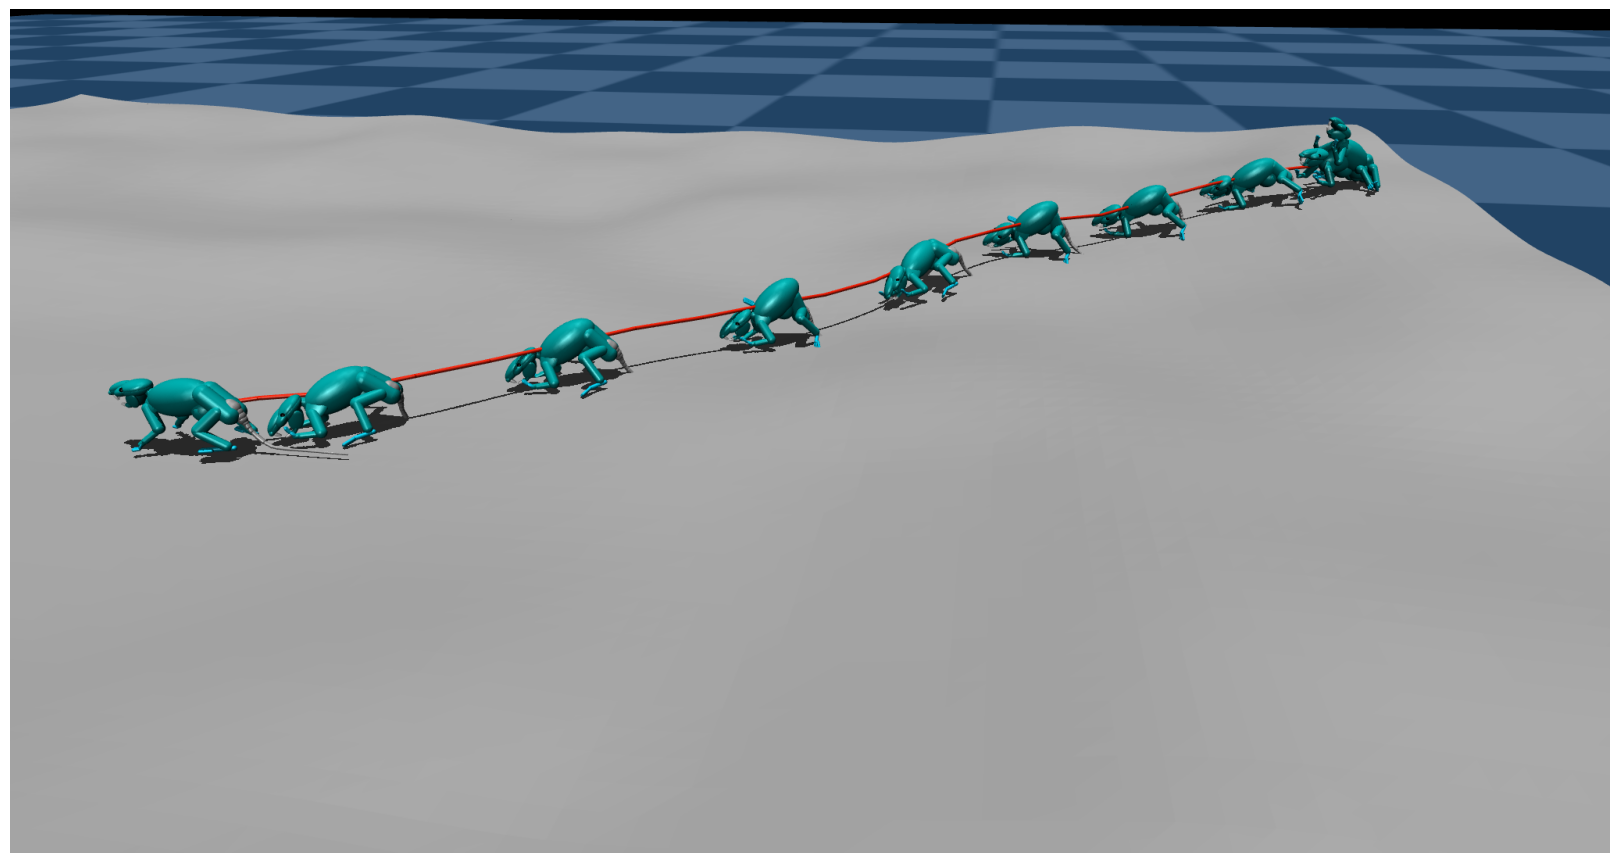

In [16]:
assert (
    captured_cam
), "Click 'Capture Camera' in the widget above before running this cell"

print(
    f"Azimuth: {captured_cam['azimuth']:.1f}  Elevation: {captured_cam['elevation']:.1f}  "
    f"Distance: {captured_cam['distance']:.2f}  Lookat: {captured_cam['lookat']}"
)

# Render at full resolution using the captured free camera
hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam["azimuth"]
hires_cam.elevation = captured_cam["elevation"]
hires_cam.distance = captured_cam["distance"]
hires_cam.lookat[:] = captured_cam["lookat"]

hires_renderer = mujoco.Renderer(
    trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH
)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

# Display and save
run_id = Path(CHECKPOINT_PATH).name
save_name = f"trail_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

fig.savefig(OUTPUT_DIR / f"{save_name}.pdf", bbox_inches="tight", pad_inches=0)
fig.savefig(OUTPUT_DIR / f"{save_name}.svg", bbox_inches="tight", pad_inches=0)
fig.savefig(OUTPUT_DIR / f"{save_name}.png", bbox_inches="tight", pad_inches=0)
print(f"Saved to {OUTPUT_DIR / save_name}.[pdf|svg|png]")
plt.show()